# 04 — Đánh giá bổ sung, cải tiến & so sánh mô hình

Notebook này bổ sung các phần mà bộ tiêu chí chấm yêu cầu nhưng notebook 02 chưa có:

| Mục | Nội dung | Tiêu chí |
|---|---|---|
| 1 | Bảng mục tiêu – chỉ số | BKT1 #2 |
| 2 | **Mô hình cơ sở (baseline)**: trung vị; đơn giá trung vị quận × diện tích | BKT2 #2, BKT cuối #4 |
| 3 | **Kiểm định chéo 5-fold trên tập train**: trung bình ± độ lệch chuẩn, train vs validation | BKT2 #5, #7; BKT3 #7 |
| 4 | Đánh giá trên tập test + **biểu đồ phần dư** | BKT2 #6 |
| 5 | Kiểm tra cách chia dữ liệu: ngẫu nhiên vs **phân tầng theo quận** vs **theo thời gian** | BKT1 #8 |
| 6 | Bảng **hạn chế – giải pháp** | BKT3 #1, #2 |
| 7 | Cải tiến đặc trưng: **Target Encoding** cho phường | BKT3 #3 |
| 8 | Thuật toán mới: **Gradient Boosting** + **tối ưu siêu tham số** (RandomizedSearchCV); tối ưu Random Forest | BKT3 #4, #5 |
| 9 | **Ablation**: đóng góp của từng nhóm đặc trưng | BKT3 #6 |
| 10 | Bảng so sánh cuối (cùng dữ liệu, cùng fold, cùng chỉ số) & chọn mô hình cuối | BKT3 #6–#9 |
| 11 | Lưu mô hình mới cho demo | — |

**Nguyên tắc:** tập test **chỉ** dùng ở bước đánh giá cuối; mọi lựa chọn (siêu tham số, đặc trưng) dựa trên kiểm định chéo trong tập train. Tất cả dùng chung `SEED = 42` và **cùng 5 fold**.

⏱ Thời gian chạy: khoảng 12 phút trên CPU 12 luồng (đo khi chạy lại); trên Colab CPU có thể 25–40 phút.

In [1]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn
from scipy.stats import loguniform, randint
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, TargetEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate, RandomizedSearchCV, train_test_split
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Có thể đặt biến môi trường ML_PROJECT_DIR để chạy trên máy khác (không phụ thuộc đường dẫn cá nhân)
def find_project_dir():
    # Thứ tự ưu tiên: (1) biến môi trường ML_PROJECT_DIR; (2) Colab: thư mục dự án trên Google Drive;
    # (3) chạy trên máy: thư mục gốc dự án (nơi có requirements.txt) — thư mục hiện tại hoặc thư mục cha
    if os.environ.get("ML_PROJECT_DIR"):
        return os.environ["ML_PROJECT_DIR"]
    if IN_COLAB:
        return "/content/drive/MyDrive/ML_house_price"
    here = os.path.abspath(os.getcwd())
    for p in (here, os.path.dirname(here)):
        if os.path.isfile(os.path.join(p, "requirements.txt")):
            return p
    return here

PROJECT_DIR = find_project_dir()
DATA_DIR, MODEL_DIR = f"{PROJECT_DIR}/data_processed", f"{PROJECT_DIR}/models"
RES_DIR, FIG_DIR = f"{PROJECT_DIR}/results/04", f"{PROJECT_DIR}/figures/04"
for d in [RES_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
N_FOLDS = 5
MIN_FREQ = 30
RF_SAMPLE = 50_000        # Random Forest học trên mẫu con trong mỗi fold (như notebook 02)
TUNE_SAMPLE = 100_000     # mẫu con để tìm siêu tham số (chỉ lấy từ tập train)
N_ITER_HGB, N_ITER_RF = 12, 8
print("sklearn", sklearn.__version__, "|", PROJECT_DIR)

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)

def save_table(df, name, index=True):
    p = os.path.join(RES_DIR, f"{name}.csv"); df.to_csv(p, index=index, encoding="utf-8-sig"); print("Đã lưu:", p)

sklearn 1.6.1 | D:\HocMay_GiaNha_KT1


In [2]:
cfg = json.load(open(os.path.join(DATA_DIR, "feature_config.json"), encoding="utf-8"))
NUM, BIN = cfg["num_features"], cfg["bin_features"]
CAT = ["district_key", "ward_loc", "house_direction", "road_type"]
FEATURES = NUM + BIN + CAT

def prepare(df):
    df = df.copy()
    for c in ["district_key", "ward_new", "house_direction", "road_type"]:
        df[c] = df[c].fillna("unknown").astype(str).replace("", "unknown")
    df["ward_loc"] = df["district_key"] + " | " + df["ward_new"]
    for c in BIN:
        df[c] = df[c].fillna(0).astype(int)
    return df

train = prepare(pd.read_parquet(os.path.join(DATA_DIR, "train.parquet")))
test  = prepare(pd.read_parquet(os.path.join(DATA_DIR, "test.parquet")))
X_train, y_train = train[FEATURES], train["price"].to_numpy()
X_test,  y_test  = test[FEATURES],  test["price"].to_numpy()

# Siêu tham số α đã chọn bằng kiểm định chéo ở notebook 02 (đọc từ mô hình đã lưu)
def _reg(f):
    return joblib.load(os.path.join(MODEL_DIR, f)).regressor_.named_steps["reg"]
ALPHA = {"Ridge": float(_reg("ridge.joblib").alpha_ if hasattr(_reg("ridge.joblib"), "alpha_") else _reg("ridge.joblib").alpha),
         "Lasso": float(_reg("lasso.joblib").alpha_), "Lasso (1-SE)": float(_reg("lasso_1se.joblib").alpha)}
_en = _reg("elastic_net.joblib"); ALPHA["Elastic Net"] = (float(_en.alpha_), float(_en.l1_ratio_))
print("α từ notebook 02:", ALPHA)
print(f"Train {X_train.shape} | Test {X_test.shape}")

CV = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(CV.split(X_train))          # dùng CHUNG cho mọi mô hình → so sánh công bằng

α từ notebook 02: {'Ridge': 1.3894954943731375, 'Lasso': 3.0888435964774785e-06, 'Lasso (1-SE)': 0.00015998587196060574, 'Elastic Net': (4.094915062380427e-06, 0.9)}
Train (312092, 17) | Test (78077, 17)


## 1. Mục tiêu – chỉ số

| Mục tiêu thực tế | Mục tiêu học máy | Chỉ số | Mức mong muốn / tham chiếu |
|---|---|---|---|
| Ước lượng giá rao bán hợp lý cho một căn nhà ở Hà Nội | Hồi quy log(giá) từ đặc điểm nhà | **MAPE** (chỉ số chính) — sai số tương đối, dễ hiểu ("lệch trung bình x%"), không phụ thuộc mức giá | MAPE test **≤ 25%** và **thấp hơn baseline "đơn giá quận × diện tích" ít nhất 5 điểm %** |
| Không sai lệch quá lớn với căn đắt | | **RMSE** (tỷ) — phạt nặng sai số lớn | Thấp hơn baseline |
| Sai số điển hình với người dùng | | **MAE**, **MdAPE** (trung vị % sai số) | MdAPE ≤ 20% |
| Hiểu được yếu tố nào quyết định giá | Mô hình diễn giải được | Số đặc trưng giữ lại (Lasso), độ ổn định hệ số | Giữ được độ chính xác khi giảm số đặc trưng |
| Mô hình ổn định, không học thuộc | Không quá khớp | Độ lệch chuẩn qua 5 fold; chênh lệch train – validation | std MAPE < 0,5 điểm %; chênh lệch train – val < 3 điểm % |

**Vì sao không dùng R² làm chỉ số chính:** R² trên log(giá) đã ~0,84 nhưng không cho người dùng biết sai bao nhiêu tiền hay bao nhiêu %; MAPE trả lời trực tiếp câu hỏi đó.
**Vì sao chiến lược hold-out 80/20 + 5-fold CV:** dữ liệu lớn (390 nghìn tin) nên tập test 78 nghìn tin cho ước lượng rất ổn định; CV 5-fold trên train dùng để chọn siêu tham số và đo độ ổn định mà không chạm tập test.

## 2. Mô hình cơ sở (baseline)

| Baseline | Cách dự đoán | Ý nghĩa |
|---|---|---|
| **Trung vị** (`DummyRegressor`) | Mọi căn = giá trung vị tập train | Mức "không học gì" |
| **Đơn giá quận × diện tích** | Giá = diện tích × đơn giá trung vị của quận (học từ train) | Cách định giá "kinh nghiệm" của người môi giới — baseline **khó** hơn, có ý nghĩa thực tế |

In [3]:
class DistrictUnitPrice(BaseEstimator, RegressorMixin):
    # Baseline: giá = diện tích × đơn giá trung vị (VND/m²) của quận, học từ dữ liệu huấn luyện
    def fit(self, X, y):
        area = np.exp(X["log_area"].to_numpy())
        unit = pd.Series(np.asarray(y) / area, index=X.index)
        self.unit_by_district_ = unit.groupby(X["district_key"].values).median().to_dict()
        self.global_unit_ = float(unit.median())
        self.global_price_ = float(np.median(y))
        return self
    def predict(self, X):
        u = X["district_key"].map(self.unit_by_district_).fillna(self.global_unit_).to_numpy()
        area = np.exp(X["log_area"].to_numpy())
        return np.where(np.isnan(area), self.global_price_, area * u)

def build_preprocessor(drop=None, min_freq=MIN_FREQ, num=None, bin_=None, cat=None, indicator=True, target_encode=None):
    num = NUM if num is None else num; bin_ = BIN if bin_ is None else bin_; cat = CAT if cat is None else cat
    parts = []
    if num:
        parts.append(("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=indicator), StandardScaler()), num))
    if bin_:
        parts.append(("bin", "passthrough", bin_))
    oh = [c for c in cat if c not in (target_encode or [])]
    if oh:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq,
                                           drop=drop, sparse_output=False), oh))
    if target_encode:
        parts.append(("te", make_pipeline(TargetEncoder(target_type="continuous", random_state=SEED), StandardScaler()), target_encode))
    return ColumnTransformer(parts, sparse_threshold=0)

def ttr(pipe):
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp, check_inverse=False)

def linear(reg, drop=None, **kw):
    return ttr(Pipeline([("pre", build_preprocessor(drop=drop, **kw)), ("reg", reg)]))

class Subsample(BaseEstimator, RegressorMixin):
    # Huấn luyện estimator trên mẫu con ngẫu nhiên n dòng của dữ liệu được đưa vào (dùng cho Random Forest)
    def __init__(self, estimator=None, n=RF_SAMPLE, random_state=SEED):
        self.estimator, self.n, self.random_state = estimator, n, random_state
    def fit(self, X, y):
        idx = np.random.default_rng(self.random_state).choice(len(X), size=min(self.n, len(X)), replace=False)
        self.estimator_ = clone(self.estimator).fit(X.iloc[idx], np.asarray(y)[idx])
        return self
    def predict(self, X):
        return self.estimator_.predict(X)

a_en, r_en = ALPHA["Elastic Net"]
CANDIDATES = {
    "Baseline: trung vị":            DummyRegressor(strategy="median"),
    "Baseline: đơn giá quận × DT":   DistrictUnitPrice(),
    "Linear Regression":             linear(LinearRegression(), drop="first"),
    "Ridge":                         linear(Ridge(alpha=ALPHA["Ridge"])),
    "Lasso":                         linear(Lasso(alpha=ALPHA["Lasso"], precompute=True, max_iter=20_000)),
    "Lasso (1-SE)":                  linear(Lasso(alpha=ALPHA["Lasso (1-SE)"], precompute=True, max_iter=20_000)),
    "Elastic Net":                   linear(ElasticNet(alpha=a_en, l1_ratio=r_en, precompute=True, max_iter=20_000)),
    "Random Forest (mặc định NB02)": Subsample(ttr(Pipeline([("pre", build_preprocessor()), ("reg", RandomForestRegressor(
                                         n_estimators=150, min_samples_leaf=3, max_features=0.33, n_jobs=-1, random_state=SEED))]))),
}

## 3. Kiểm định chéo 5-fold trên tập train
Mỗi mô hình được huấn luyện 5 lần trên 4/5 tập train và đánh giá trên 1/5 còn lại (**cùng 5 fold cho mọi mô hình**). Báo cáo **trung bình ± độ lệch chuẩn** và cả sai số trên phần huấn luyện để nhận diện quá khớp.

> Với Random Forest (học trên mẫu con 50 nghìn tin trong mỗi fold), "MAPE train" được tính trên **toàn bộ** phần train của fold, trong đó phần lớn là tin mô hình không học → con số này **đánh giá thấp** mức quá khớp thật. Mức quá khớp thật của RF xem ở notebook 02 (MAPE trên chính 50 nghìn tin đã học ≈ 15% so với test ≈ 22%).

In [4]:
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "MAPE": "neg_mean_absolute_percentage_error"}

def run_cv(name, est, X=X_train, y=y_train, folds=FOLDS):
    t0 = time.time()
    r = cross_validate(est, X, y, cv=folds, scoring=SCORING, return_train_score=True, n_jobs=1)
    row = {"mô hình": name}
    for k, scale in [("MAE", 1e9), ("RMSE", 1e9), ("MAPE", 0.01)]:
        v, tr = -r[f"test_{k}"] / scale, -r[f"train_{k}"] / scale
        row[f"{k} val (mean)"], row[f"{k} val (std)"], row[f"{k} train (mean)"] = v.mean(), v.std(ddof=1), tr.mean()
    row["thời gian (s)"] = time.time() - t0
    row["_folds_MAPE"] = (-r["test_MAPE"] * 100).round(3).tolist()
    print(f"{name:32s} MAPE val {row['MAPE val (mean)']:.2f} ± {row['MAPE val (std)']:.2f}%  "
          f"(train {row['MAPE train (mean)']:.2f}%)  {row['thời gian (s)']:.0f}s")
    return row

CV_ROWS = [run_cv(n, e) for n, e in CANDIDATES.items()]

def cv_table(rows):
    t = pd.DataFrame(rows).set_index("mô hình")
    out = pd.DataFrame(index=t.index)
    out["MAPE val (%)"] = t.apply(lambda r: f"{r['MAPE val (mean)']:.2f} ± {r['MAPE val (std)']:.2f}", axis=1)
    out["MAPE train (%)"] = t["MAPE train (mean)"].round(2)
    out["chênh train–val"] = (t["MAPE val (mean)"] - t["MAPE train (mean)"]).round(2)
    out["MAE val (tỷ)"] = t.apply(lambda r: f"{r['MAE val (mean)']:.3f} ± {r['MAE val (std)']:.3f}", axis=1)
    out["RMSE val (tỷ)"] = t.apply(lambda r: f"{r['RMSE val (mean)']:.3f} ± {r['RMSE val (std)']:.3f}", axis=1)
    out["MAPE 5 fold"] = t["_folds_MAPE"].map(lambda v: ", ".join(f"{x:.2f}" for x in v))
    return out

cv_base = cv_table(CV_ROWS)
display(cv_base)
save_table(cv_base, "cv_5fold_mo_hinh_nb02_va_baseline")

Baseline: trung vị               MAPE val 55.48 ± 0.22%  (train 55.48%)  0s


Baseline: đơn giá quận × DT      MAPE val 28.40 ± 0.14%  (train 28.39%)  0s


Linear Regression                MAPE val 22.43 ± 0.08%  (train 22.40%)  28s


Ridge                            MAPE val 22.43 ± 0.08%  (train 22.40%)  11s


Lasso                            MAPE val 22.43 ± 0.08%  (train 22.40%)  15s


Lasso (1-SE)                     MAPE val 22.75 ± 0.09%  (train 22.73%)  13s


Elastic Net                      MAPE val 22.43 ± 0.08%  (train 22.40%)  15s


Random Forest (mặc định NB02)    MAPE val 21.76 ± 0.20%  (train 20.48%)  47s


,MAPE val (%),MAPE train (%),chênh train–val,MAE val (tỷ),RMSE val (tỷ),MAPE 5 fold
mô hình,,,,,,
Baseline: trung vị,55.48 ± 0.22,55.48,0.00,10.141 ± 0.113,22.512 ± 0.293,"55.33, 55.79, 55.42, 55.24, 55.63"
Baseline: đơn giá quận × DT,28.40 ± 0.14,28.39,0.01,5.813 ± 0.067,13.682 ± 0.228,"28.26, 28.63, 28.38, 28.33, 28.39"
Linear Regression,22.43 ± 0.08,22.40,0.03,4.492 ± 0.036,10.393 ± 0.087,"22.36, 22.55, 22.41, 22.36, 22.48"
Ridge,22.43 ± 0.08,22.40,0.03,4.492 ± 0.036,10.394 ± 0.089,"22.36, 22.55, 22.41, 22.35, 22.48"
Lasso,22.43 ± 0.08,22.40,0.03,4.492 ± 0.036,10.393 ± 0.090,"22.36, 22.55, 22.41, 22.35, 22.48"
Lasso (1-SE),22.75 ± 0.09,22.73,0.01,4.546 ± 0.039,10.557 ± 0.146,"22.69, 22.89, 22.70, 22.68, 22.78"
Elastic Net,22.43 ± 0.08,22.40,0.03,4.492 ± 0.036,10.393 ± 0.090,"22.36, 22.55, 22.41, 22.35, 22.48"
Random Forest (mặc định NB02),21.76 ± 0.20,20.48,1.28,4.373 ± 0.045,10.570 ± 0.186,"21.69, 22.09, 21.56, 21.74, 21.75"


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\cv_5fold_mo_hinh_nb02_va_baseline.csv


## 4. Đánh giá trên tập test & biểu đồ phần dư
Huấn luyện lại trên **toàn bộ** tập train rồi đánh giá **một lần** trên tập test.

In [5]:
def test_metrics(est):
    p = est.predict(X_test)
    e = p - y_test
    return {"MAE (tỷ)": np.mean(np.abs(e)) / 1e9, "RMSE (tỷ)": np.sqrt(np.mean(e ** 2)) / 1e9,
            "MAPE (%)": np.mean(np.abs(e) / y_test) * 100, "MdAPE (%)": np.median(np.abs(e) / y_test) * 100}, p

FITTED, TEST_ROWS, PRED = {}, [], {}
for n, e in CANDIDATES.items():
    m = clone(e).fit(X_train, y_train)
    FITTED[n] = m
    met, PRED[n] = test_metrics(m)
    TEST_ROWS.append({"mô hình": n, **met})
test_base = pd.DataFrame(TEST_ROWS).set_index("mô hình")
b = test_base.loc["Baseline: đơn giá quận × DT", "MAPE (%)"]
test_base["MAPE giảm so với baseline (điểm %)"] = b - test_base["MAPE (%)"]
display(test_base.round(3))
save_table(test_base.round(4), "test_mo_hinh_nb02_va_baseline")

,MAE (tỷ),RMSE (tỷ),MAPE (%),MdAPE (%),MAPE giảm so với baseline (điểm %)
mô hình,,,,,
Baseline: trung vị,10.075,22.294,55.706,45.882,-27.257
Baseline: đơn giá quận × DT,5.740,13.506,28.449,22.875,0.000
Linear Regression,4.456,10.384,22.443,17.193,6.007
Ridge,4.456,10.383,22.442,17.191,6.007
Lasso,4.456,10.380,22.442,17.197,6.008
Lasso (1-SE),4.504,10.489,22.733,17.406,5.716
Elastic Net,4.456,10.380,22.442,17.194,6.008
Random Forest (mặc định NB02),4.326,10.452,21.671,15.734,6.778


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\test_mo_hinh_nb02_va_baseline.csv


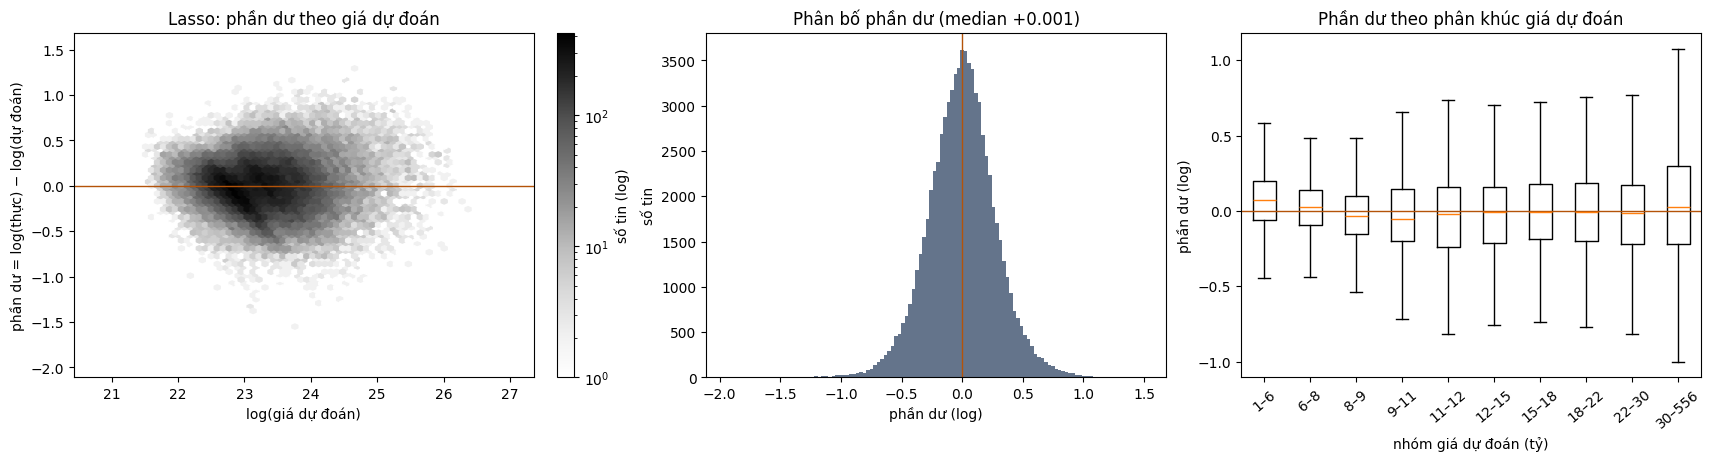

In [6]:
def residual_plots(name, pred, tag):
    lp, ly = np.log(pred), np.log(y_test)
    res = ly - lp
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")   # tự giãn để nhãn thanh màu không đè nhãn trục
    ax = axes[0]
    hb = ax.hexbin(lp, res, gridsize=70, bins="log", cmap="Greys", mincnt=1)
    ax.axhline(0, color="#b45309", lw=1)
    ax.set(xlabel="log(giá dự đoán)", ylabel="phần dư = log(thực) − log(dự đoán)", title=f"{name}: phần dư theo giá dự đoán")
    fig.colorbar(hb, ax=ax, label="số tin (log)")
    ax = axes[1]
    ax.hist(res, bins=120, color="#64748b")
    ax.axvline(0, color="#b45309", lw=1)
    ax.set(xlabel="phần dư (log)", ylabel="số tin", title=f"Phân bố phần dư (median {np.median(res):+.3f})")
    ax = axes[2]
    dec = pd.qcut(pred, 10)
    groups = [res[dec.codes == k] for k in range(10)]
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks(range(1, 11), [f"{iv.left/1e9:.0f}–{iv.right/1e9:.0f}" for iv in dec.categories], rotation=40)
    ax.axhline(0, color="#b45309", lw=1)
    ax.set(xlabel="nhóm giá dự đoán (tỷ)", ylabel="phần dư (log)", title="Phần dư theo phân khúc giá dự đoán")
    save_fig(fig, f"phan_du_{tag}")

residual_plots("Lasso", PRED["Lasso"], "lasso")

**Đọc biểu đồ phần dư:** phần dư dương = giá thực cao hơn dự đoán (mô hình định giá thấp). Nếu hộp ở nhóm giá thấp nằm dưới 0 và nhóm giá cao nằm trên 0 → mô hình **co dự đoán về giữa** (nhà rẻ bị đoán cao, nhà đắt bị đoán thấp) — dấu hiệu mô hình tuyến tính chưa nắm hết quan hệ phi tuyến ở hai đầu phân khúc.

## 5. Kiểm tra cách chia dữ liệu
Dữ liệu có yếu tố **địa bàn** (quận) và **thời gian** (6/2025 – 3/2026). So sánh 3 cách chia (cùng mô hình Lasso, cùng α):
- **Ngẫu nhiên** 80/20 (đang dùng).
- **Phân tầng theo quận**: mỗi quận giữ đúng tỷ lệ 80/20 → quận ít tin vẫn có mặt ở cả hai tập.
- **Theo thời gian**: huấn luyện tin đăng **trước 2026**, kiểm tra tin **từ 1/2026** → mô phỏng dùng mô hình cho tin đăng mới trong tương lai.

,số tin train,số tin test,MAPE (%),MdAPE (%)
cách chia,,,,
Ngẫu nhiên 80/20 (đang dùng),312092,78077,22.442,17.197
Phân tầng theo quận 80/20,312135,78034,22.449,17.254
"Theo thời gian (train < 2026-01-01, test ≥)",315416,73700,22.464,18.566


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\so_sanh_cach_chia_du_lieu.csv


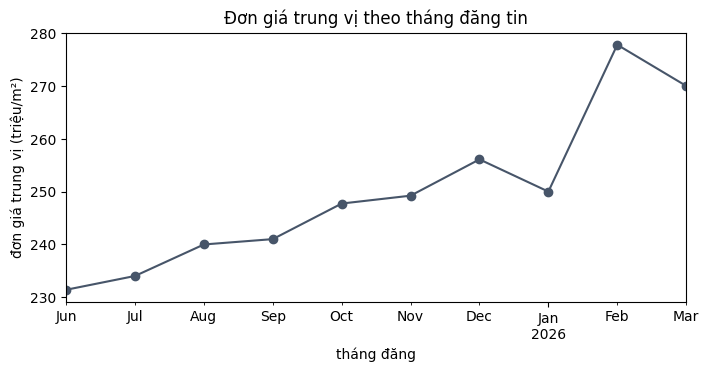

In [7]:
full = pd.concat([train, test], ignore_index=True)
full["date"] = pd.to_datetime(full["date"], errors="coerce")
lasso_tpl = CANDIDATES["Lasso"]

def eval_split(name, tr_idx, te_idx):
    m = clone(lasso_tpl).fit(full.loc[tr_idx, FEATURES], full.loc[tr_idx, "price"].to_numpy())
    yt = full.loc[te_idx, "price"].to_numpy(); p = m.predict(full.loc[te_idx, FEATURES])
    return {"cách chia": name, "số tin train": len(tr_idx), "số tin test": len(te_idx),
            "MAPE (%)": np.mean(np.abs(p - yt) / yt) * 100, "MdAPE (%)": np.median(np.abs(p - yt) / yt) * 100}

rows = [eval_split("Ngẫu nhiên 80/20 (đang dùng)", train.index.to_numpy(), np.arange(len(train), len(full)))]
counts = full["district_key"].value_counts()
strat = full["district_key"].where(full["district_key"].map(counts) >= 10, "khac")
tr_s, te_s = train_test_split(full.index.to_numpy(), test_size=0.2, random_state=SEED, stratify=strat)
rows.append(eval_split("Phân tầng theo quận 80/20", tr_s, te_s))
cut = pd.Timestamp("2026-01-01")
tr_t = full.index[full["date"] < cut].to_numpy(); te_t = full.index[full["date"] >= cut].to_numpy()
if len(te_t) > 1000:
    rows.append(eval_split(f"Theo thời gian (train < {cut.date()}, test ≥)", tr_t, te_t))
split_tab = pd.DataFrame(rows).set_index("cách chia")
display(split_tab.round(3))
save_table(split_tab.round(4), "so_sanh_cach_chia_du_lieu")

by_month = full.groupby(full["date"].dt.to_period("M"))["unit_price"].median() / 1e6
fig, ax = plt.subplots(figsize=(8, 3.5))
by_month.plot(ax=ax, marker="o", color="#475569")
ax.set(xlabel="tháng đăng", ylabel="đơn giá trung vị (triệu/m²)", title="Đơn giá trung vị theo tháng đăng tin")
save_fig(fig, "don_gia_theo_thang")

**Nhận xét cần viết vào báo cáo:** nếu 3 cách chia cho MAPE chênh nhau rất ít → kết quả **không phụ thuộc cách chia**, việc chia ngẫu nhiên là chấp nhận được (khử trùng lặp đã được làm *trước* khi chia nên không có rò rỉ do tin đăng lại). Nếu chia theo thời gian cho MAPE cao hơn rõ → có **trôi giá theo thời gian** (xem biểu đồ đơn giá theo tháng): khi triển khai thực tế cần huấn luyện lại định kỳ.

## 6. Hạn chế của mô hình ban đầu → giải pháp

| # | Hạn chế (bằng chứng) | Giải pháp | Cơ sở lý thuyết | Mục thực hiện |
|---|---|---|---|---|
| 1 | Mô hình tuyến tính **co dự đoán về giữa**: sai số cao ở nhà < 6 tỷ và > 32 tỷ (MAPE theo phân khúc, biểu đồ phần dư) | Mô hình **phi tuyến** dạng cây tăng cường: Gradient Boosting | Cây quyết định học được ngưỡng & tương tác (ví dụ: tác động của diện tích khác nhau giữa các quận) mà mô hình cộng tính tuyến tính không biểu diễn được | Mục 8 |
| 2 | **Phường hiếm** bị gộp chung (`min_frequency=30`) → mất thông tin vị trí chi tiết; one-hot ~230 cột phường làm mô hình cồng kềnh | **Target Encoding** phường (mã hoá bằng giá trung bình có làm trơn, *cross-fitting* để tránh rò rỉ) | Mã hoá theo mục tiêu nén biến phân loại nhiều giá trị thành 1 cột số; làm trơn (shrinkage) về trung bình chung cho phường ít tin | Mục 7 |
| 3 | Random Forest **quá khớp** (MAPE train ~15% vs test ~22%) và chưa tối ưu siêu tham số | **RandomizedSearchCV** cho `min_samples_leaf`, `max_features`, `max_depth` | Lá lớn hơn / ít đặc trưng mỗi lần tách → giảm phương sai | Mục 8 |
| 4 | Chưa biết nhóm đặc trưng nào thực sự đóng góp | **Ablation**: bỏ từng nhóm và đo lại | Đo tác động biên của từng nhóm trong cùng điều kiện | Mục 9 |

## 7. Cải tiến đặc trưng: Target Encoding cho phường
So sánh (cùng 5 fold, cùng Ridge α): **one-hot** phường (hiện tại) vs **target encoding** phường. `TargetEncoder` của scikit-learn dùng *cross-fitting* nội bộ khi huấn luyện nên giá trị mã hoá của một tin không dùng chính giá của tin đó → không rò rỉ nhãn.

In [8]:
FE_CANDS = {
    "Ridge — one-hot phường (hiện tại)": linear(Ridge(alpha=ALPHA["Ridge"])),
    "Ridge — target encoding phường":    linear(Ridge(alpha=ALPHA["Ridge"]), target_encode=["ward_loc"]),
}
FE_ROWS = [run_cv(n, e) for n, e in FE_CANDS.items()]
fe_tab = cv_table(FE_ROWS)
n_cols = {n: len(clone(e.regressor.named_steps["pre"]).fit(X_train, np.log(y_train)).get_feature_names_out())
          for n, e in FE_CANDS.items()}
fe_tab["số cột đặc trưng"] = pd.Series(n_cols)
display(fe_tab)
save_table(fe_tab, "cai_tien_target_encoding")

Ridge — one-hot phường (hiện tại) MAPE val 22.43 ± 0.08%  (train 22.40%)  11s


Ridge — target encoding phường   MAPE val 22.73 ± 0.09%  (train 22.71%)  6s


,MAPE val (%),MAPE train (%),chênh train–val,MAE val (tỷ),RMSE val (tỷ),MAPE 5 fold,số cột đặc trưng
mô hình,,,,,,,
Ridge — one-hot phường (hiện tại),22.43 ± 0.08,22.40,0.03,4.492 ± 0.036,10.394 ± 0.089,"22.36, 22.55, 22.41, 22.35, 22.48",311
Ridge — target encoding phường,22.73 ± 0.09,22.71,0.02,4.529 ± 0.038,10.454 ± 0.114,"22.69, 22.86, 22.69, 22.64, 22.77",58


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\cai_tien_target_encoding.csv


## 8. Thuật toán mới: Gradient Boosting + tối ưu siêu tham số

**HistGradientBoostingRegressor:** cộng dồn nhiều cây nông, mỗi cây học phần sai số còn lại của các cây trước (boosting) — khác Random Forest (bagging: nhiều cây sâu độc lập rồi lấy trung bình). Biến phân loại được xử lý **trực tiếp** (không cần one-hot), giá trị thiếu được xử lý tự nhiên.

Tìm siêu tham số bằng **RandomizedSearchCV** (3-fold) trên mẫu con `TUNE_SAMPLE` tin **lấy từ tập train**; tập test không tham gia.

| Siêu tham số | Vai trò | Không gian tìm |
|---|---|---|
| `learning_rate` | Bước học mỗi cây; nhỏ → cần nhiều cây hơn nhưng tổng quát tốt hơn | log-uniform 0,03 – 0,3 |
| `max_iter` | Số cây | 300, 600, 900 |
| `max_leaf_nodes` | Độ phức tạp mỗi cây | 15 – 127 |
| `min_samples_leaf` | Số mẫu tối thiểu mỗi lá → chống quá khớp | 20 – 300 |
| `l2_regularization` | Phạt L2 trên giá trị lá | log-uniform 0,001 – 10 |

In [9]:
CAT_IDX = list(range(len(NUM) + len(BIN), len(NUM) + len(BIN) + len(CAT)))
def tree_pre():
    return ColumnTransformer([("num", "passthrough", NUM), ("bin", "passthrough", BIN),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                     encoded_missing_value=-1, min_frequency=MIN_FREQ, max_categories=250), CAT)],
                             sparse_threshold=0)
def hgb(**kw):
    return ttr(Pipeline([("pre", tree_pre()),
                         ("reg", HistGradientBoostingRegressor(categorical_features=CAT_IDX, random_state=SEED, **kw))]))

tune_idx = np.random.default_rng(SEED).choice(len(X_train), size=min(TUNE_SAMPLE, len(X_train)), replace=False)
Xt, yt = X_train.iloc[tune_idx], y_train[tune_idx]
space_hgb = {"regressor__reg__learning_rate": loguniform(0.03, 0.3), "regressor__reg__max_iter": [300, 600, 900],
             "regressor__reg__max_leaf_nodes": randint(15, 128), "regressor__reg__min_samples_leaf": randint(20, 301),
             "regressor__reg__l2_regularization": loguniform(1e-3, 10)}
t0 = time.time()
search_hgb = RandomizedSearchCV(hgb(), space_hgb, n_iter=N_ITER_HGB, cv=3, scoring="neg_mean_absolute_percentage_error",
                                random_state=SEED, n_jobs=1, return_train_score=True).fit(Xt, yt)
print(f"HGB: {time.time()-t0:.0f}s | MAPE CV tốt nhất {-search_hgb.best_score_*100:.2f}%")
best_hgb = {k.split("__")[-1]: v for k, v in search_hgb.best_params_.items()}
print("Siêu tham số tốt nhất:", best_hgb)

space_rf = {"regressor__reg__min_samples_leaf": [1, 3, 5, 10, 20], "regressor__reg__max_features": [0.2, 0.33, 0.5, 0.7],
            "regressor__reg__max_depth": [None, 20, 30]}
rf_tpl = ttr(Pipeline([("pre", build_preprocessor()), ("reg", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=SEED))]))
rf_idx = tune_idx[:min(RF_SAMPLE, len(tune_idx))]
t0 = time.time()
search_rf = RandomizedSearchCV(rf_tpl, space_rf, n_iter=N_ITER_RF, cv=3, scoring="neg_mean_absolute_percentage_error",
                               random_state=SEED, n_jobs=1, return_train_score=True).fit(X_train.iloc[rf_idx], y_train[rf_idx])
print(f"RF: {time.time()-t0:.0f}s | MAPE CV tốt nhất {-search_rf.best_score_*100:.2f}%")
best_rf = {k.split("__")[-1]: v for k, v in search_rf.best_params_.items()}
print("Siêu tham số tốt nhất:", best_rf)

def search_table(s, name):
    t = pd.DataFrame(s.cv_results_)
    cols = [c for c in t.columns if c.startswith("param_")]
    t = t[cols + ["mean_test_score", "std_test_score", "mean_train_score"]].copy()
    t["MAPE val (%)"] = -t["mean_test_score"] * 100; t["std (%)"] = t["std_test_score"] * 100
    t["MAPE train (%)"] = -t["mean_train_score"] * 100
    t = t.drop(columns=["mean_test_score", "std_test_score", "mean_train_score"]).sort_values("MAPE val (%)")
    t.columns = [c.replace("param_regressor__reg__", "") for c in t.columns]
    save_table(t.round(4), f"tim_sieu_tham_so_{name}", index=False)
    return t
display(search_table(search_hgb, "hgb").head(8).round(3))
display(search_table(search_rf, "rf").head(8).round(3))

HGB: 84s | MAPE CV tốt nhất 19.75%
Siêu tham số tốt nhất: {'l2_regularization': np.float64(0.29507066707905333), 'learning_rate': np.float64(0.12268018301895914), 'max_iter': 300, 'max_leaf_nodes': 122, 'min_samples_leaf': 68}


RF: 88s | MAPE CV tốt nhất 21.58%
Siêu tham số tốt nhất: {'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}
Đã lưu: D:\HocMay_GiaNha_KT1/results/04\tim_sieu_tham_so_hgb.csv


,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAPE val (%),std (%),MAPE train (%)
4,0.295,0.123,300,122,68,19.750,0.124,16.127
1,0.244,0.084,900,89,107,19.753,0.128,16.877
5,0.126,0.075,900,76,194,19.780,0.179,17.045
7,0.005,0.035,300,74,33,19.815,0.110,17.572
11,0.154,0.046,900,32,237,19.948,0.171,17.901
2,0.022,0.042,900,36,277,19.980,0.098,18.031
10,4.338,0.054,600,20,73,20.063,0.131,18.270
0,0.031,0.268,900,86,208,20.127,0.163,17.082


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\tim_sieu_tham_so_rf.csv


,min_samples_leaf,max_features,max_depth,MAPE val (%),std (%),MAPE train (%)
1,1,0.33,None,21.584,0.233,7.800
0,1,0.20,None,21.648,0.165,7.857
3,1,0.33,30,21.692,0.206,9.612
2,3,0.70,20,22.296,0.223,15.844
4,10,0.50,None,23.695,0.337,20.912
6,10,0.50,20,23.767,0.303,21.136
7,10,0.33,30,23.897,0.310,21.471
5,20,0.50,30,24.761,0.349,23.209


Gradient Boosting (tối ưu)       MAPE val 18.49 ± 0.11%  (train 16.18%)  38s


Random Forest (tối ưu)           MAPE val 20.99 ± 0.19%  (train 18.31%)  65s


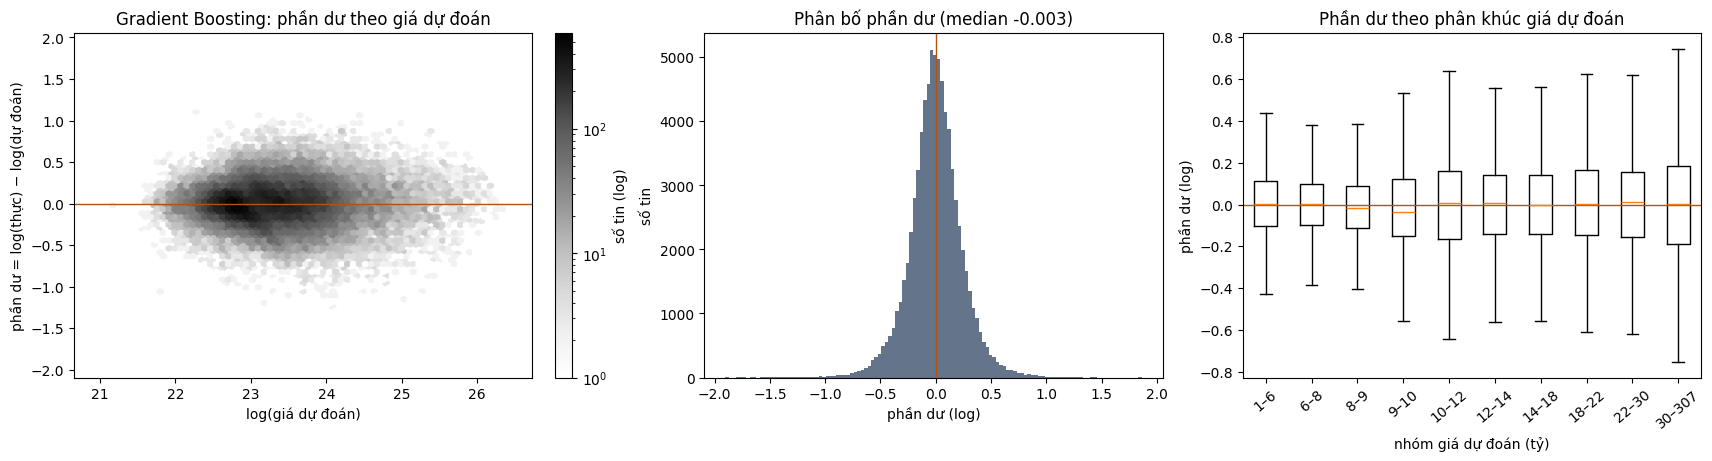

In [10]:
NEW = {
    "Gradient Boosting (tối ưu)": hgb(**best_hgb),
    "Random Forest (tối ưu)": Subsample(ttr(Pipeline([("pre", build_preprocessor()),
                                  ("reg", RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=SEED, **best_rf))]))),
}
NEW_ROWS = [run_cv(n, e) for n, e in NEW.items()]
for n, e in NEW.items():
    m = clone(e).fit(X_train, y_train); FITTED[n] = m
    met, PRED[n] = test_metrics(m); TEST_ROWS.append({"mô hình": n, **met})
residual_plots("Gradient Boosting", PRED["Gradient Boosting (tối ưu)"], "hgb")

## 9. Ablation: mỗi nhóm đặc trưng đóng góp bao nhiêu?
Cùng mô hình **Lasso (α từ notebook 02)**, cùng 5 fold; mỗi lần bỏ **một** nhóm đặc trưng. Δ MAPE > 0 nghĩa là bỏ nhóm đó làm mô hình **kém đi** → nhóm có ích.

Đầy đủ                           MAPE val 22.43 ± 0.08%  (train 22.40%)  16s


− cờ văn bản (7 cờ)              MAPE val 24.24 ± 0.12%  (train 24.21%)  15s


− phường (chỉ giữ quận)          MAPE val 24.23 ± 0.08%  (train 24.22%)  6s


− quận và phường (không có vị trí) MAPE val 29.16 ± 0.18%  (train 29.16%)  4s


− cờ thiếu dữ liệu (missing indicator) MAPE val 22.62 ± 0.08%  (train 22.59%)  15s


− hướng nhà & loại đường         MAPE val 22.62 ± 0.08%  (train 22.59%)  13s


− diện tích                      MAPE val 36.95 ± 0.38%  (train 36.89%)  15s


,MAPE val (%),Δ MAPE so với đầy đủ (điểm %)
mô hình,,
Đầy đủ,22.43 ± 0.08,0.00
− cờ văn bản (7 cờ),24.24 ± 0.12,1.81
− phường (chỉ giữ quận),24.23 ± 0.08,1.80
− quận và phường (không có vị trí),29.16 ± 0.18,6.73
− cờ thiếu dữ liệu (missing indicator),22.62 ± 0.08,0.19
− hướng nhà & loại đường,22.62 ± 0.08,0.19
− diện tích,36.95 ± 0.38,14.52


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\ablation_nhom_dac_trung.csv


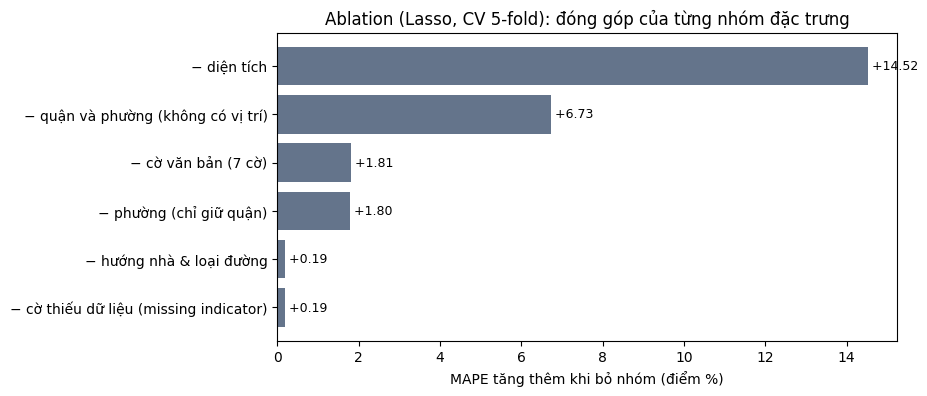

In [11]:
L = lambda **kw: linear(Lasso(alpha=ALPHA["Lasso"], precompute=True, max_iter=20_000), **kw)
ABL = {
    "Đầy đủ": L(),
    "− cờ văn bản (7 cờ)": L(bin_=[]),
    "− phường (chỉ giữ quận)": L(cat=[c for c in CAT if c != "ward_loc"]),
    "− quận và phường (không có vị trí)": L(cat=["house_direction", "road_type"]),
    "− cờ thiếu dữ liệu (missing indicator)": L(indicator=False),
    "− hướng nhà & loại đường": L(cat=["district_key", "ward_loc"]),
    "− diện tích": L(num=[c for c in NUM if c != "log_area"]),
}
ABL_ROWS = [run_cv(n, e) for n, e in ABL.items()]
abl = pd.DataFrame(ABL_ROWS).set_index("mô hình")
abl_tab = pd.DataFrame({"MAPE val (%)": abl.apply(lambda r: f"{r['MAPE val (mean)']:.2f} ± {r['MAPE val (std)']:.2f}", axis=1),
                        "Δ MAPE so với đầy đủ (điểm %)": (abl["MAPE val (mean)"] - abl.loc["Đầy đủ", "MAPE val (mean)"]).round(2)})
display(abl_tab)
save_table(abl_tab, "ablation_nhom_dac_trung")

d = abl_tab["Δ MAPE so với đầy đủ (điểm %)"].drop("Đầy đủ").sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(d.index, d.values, color="#64748b")
for i, v in enumerate(d.values):
    ax.text(v, i, f" {v:+.2f}", va="center", fontsize=9)
ax.set(xlabel="MAPE tăng thêm khi bỏ nhóm (điểm %)", title="Ablation (Lasso, CV 5-fold): đóng góp của từng nhóm đặc trưng")
save_fig(fig, "ablation")

## 10. Bảng so sánh cuối & chọn mô hình
Mọi mô hình: **cùng tập train/test, cùng 5 fold, cùng chỉ số.**

,MAPE val (%),MAPE train (%),chênh train–val,MAE (tỷ),RMSE (tỷ),MAPE (%),MdAPE (%),giảm MAPE so với baseline (điểm %),chênh CV–test (điểm %)
mô hình,,,,,,,,,
Gradient Boosting (tối ưu),18.49 ± 0.11,16.18,2.31,3.635,8.350,18.392,13.438,10.06,-0.10
Random Forest (tối ưu),20.99 ± 0.19,18.31,2.68,4.144,9.873,20.966,15.028,7.48,-0.02
Random Forest (mặc định NB02),21.76 ± 0.20,20.48,1.28,4.326,10.452,21.671,15.734,6.78,-0.09
Ridge,22.43 ± 0.08,22.40,0.03,4.456,10.383,22.442,17.191,6.01,0.01
Lasso,22.43 ± 0.08,22.40,0.03,4.456,10.380,22.442,17.197,6.01,0.01
Elastic Net,22.43 ± 0.08,22.40,0.03,4.456,10.380,22.442,17.194,6.01,0.01
Linear Regression,22.43 ± 0.08,22.40,0.03,4.456,10.384,22.443,17.193,6.01,0.01
Lasso (1-SE),22.75 ± 0.09,22.73,0.01,4.504,10.489,22.733,17.406,5.72,-0.01
Baseline: đơn giá quận × DT,28.40 ± 0.14,28.39,0.01,5.740,13.506,28.449,22.875,0.00,0.05


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\bang_so_sanh_cuoi.csv


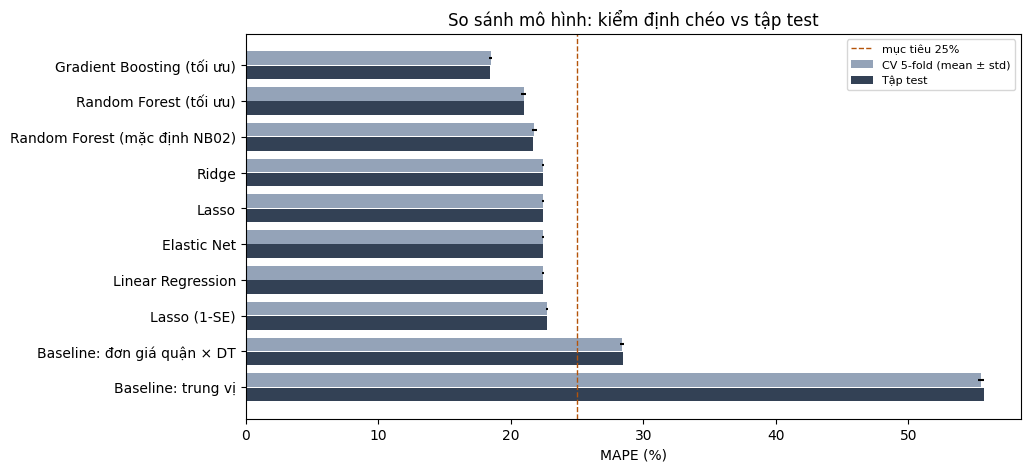

Mô hình có MAPE test thấp nhất: Gradient Boosting (tối ưu) (18.39%), giảm 10.06 điểm % so với baseline đơn giá quận × diện tích.


In [12]:
cv_all = cv_table(CV_ROWS + NEW_ROWS)
test_all = pd.DataFrame(TEST_ROWS).drop_duplicates("mô hình", keep="last").set_index("mô hình")
b = test_all.loc["Baseline: đơn giá quận × DT", "MAPE (%)"]
final = cv_all[["MAPE val (%)", "MAPE train (%)", "chênh train–val"]].join(test_all.round(3))
final["giảm MAPE so với baseline (điểm %)"] = (b - final["MAPE (%)"]).round(2)
cvm = pd.DataFrame(CV_ROWS + NEW_ROWS).set_index("mô hình")["MAPE val (mean)"]
final["chênh CV–test (điểm %)"] = (final["MAPE (%)"] - cvm).round(2)
final = final.sort_values("MAPE (%)")
display(final)
save_table(final, "bang_so_sanh_cuoi")

fig, ax = plt.subplots(figsize=(10, 5))
cvs = pd.DataFrame(CV_ROWS + NEW_ROWS).set_index("mô hình").loc[final.index]
y = np.arange(len(final))
ax.barh(y - 0.2, cvs["MAPE val (mean)"], height=0.38, xerr=cvs["MAPE val (std)"], color="#94a3b8", label="CV 5-fold (mean ± std)")
ax.barh(y + 0.2, final["MAPE (%)"], height=0.38, color="#334155", label="Tập test")
ax.set_yticks(y, final.index); ax.invert_yaxis()
ax.axvline(25, ls="--", color="#b45309", lw=1, label="mục tiêu 25%")
ax.set(xlabel="MAPE (%)", title="So sánh mô hình: kiểm định chéo vs tập test"); ax.legend(fontsize=8)
save_fig(fig, "so_sanh_cuoi")

best = final.drop(index=[i for i in final.index if i.startswith("Baseline")]).index[0]
print(f"Mô hình có MAPE test thấp nhất: {best} ({final.loc[best, 'MAPE (%)']:.2f}%), "
      f"giảm {final.loc[best, 'giảm MAPE so với baseline (điểm %)']:.2f} điểm % so với baseline đơn giá quận × diện tích.")

### Chọn mô hình cuối — cân nhắc đánh đổi
| Tiêu chí | Lasso / Elastic Net | Gradient Boosting | Random Forest |
|---|---|---|---|
| Độ chính xác (MAPE test) | xem bảng | xem bảng | xem bảng |
| Độ ổn định (std qua fold) | xem bảng | xem bảng | xem bảng |
| Quá khớp (chênh train–val) | rất nhỏ | xem bảng | lớn |
| Thời gian huấn luyện | vài giây | vài chục giây | vài chục giây (trên mẫu con) |
| **Khả năng diễn giải** | **Cao**: hệ số = % tác động; Lasso chọn đặc trưng | Thấp (cần SHAP / permutation importance) | Thấp |

Gợi ý lập luận: nếu Gradient Boosting thắng rõ về MAPE → chọn làm **mô hình dự đoán cuối**, và giữ **Lasso** làm **mô hình giải thích** (demo dùng Lasso cho phần "vì sao ra giá này"). Nếu chênh lệch nhỏ (< 1 điểm %) → ưu tiên Lasso vì đơn giản, ổn định, diễn giải được — đúng trọng tâm đề tài chính quy hoá.

## 11. Lưu mô hình mới cho demo

In [13]:
meta_path = os.path.join(MODEL_DIR, "demo_meta.json")
meta = json.load(open(meta_path, encoding="utf-8"))
fname = "gradient_boosting.joblib"
joblib.dump(FITTED["Gradient Boosting (tối ưu)"], os.path.join(MODEL_DIR, fname), compress=3)
meta["model_files"]["Gradient Boosting"] = fname
met = test_all.loc["Gradient Boosting (tối ưu)"].to_dict()
meta["test_metrics"] = [r for r in meta["test_metrics"] if r["mô hình"] != "Gradient Boosting"] + \
                       [{"mô hình": "Gradient Boosting", **{k: round(float(v), 4) for k, v in met.items()}}]
meta["hgb_params"] = {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in best_hgb.items()}
json.dump(meta, open(meta_path, "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=float)
print("Đã lưu", fname, "và cập nhật demo_meta.json")

with open(os.path.join(PROJECT_DIR, "requirements_runtime.txt"), "w") as fh:
    import importlib.metadata as im
    for p in ["scikit-learn", "numpy", "pandas", "scipy", "pyarrow", "joblib", "matplotlib", "gradio", "plotly"]:
        try:
            fh.write(f"{p}=={im.version(p)}\n")
        except im.PackageNotFoundError:
            pass
print(open(os.path.join(PROJECT_DIR, "requirements_runtime.txt")).read())

Đã lưu gradient_boosting.joblib và cập nhật demo_meta.json
scikit-learn==1.6.1
numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
pyarrow==23.0.1
joblib==1.6.0
matplotlib==3.10.0
gradio==5.50.0
plotly==5.24.1



## 12. Kiểm tra tin gần trùng giữa tập huấn luyện và tập kiểm tra
Khử trùng lặp ở notebook 01 dùng khoá *phường + đường + diện tích + giá + số phòng ngủ + số tầng*; tin đăng lại nhưng bỏ trống số phòng/số tầng ở một lần đăng sẽ **không** bị bắt. Mục này đo phần còn sót: một tin kiểm tra được coi là **gần trùng** nếu có tin huấn luyện cùng *tiêu đề (chuẩn hoá) + diện tích + giá*. Khoá dùng cả giá nên **chỉ để chẩn đoán**, không tham gia huấn luyện. So sánh MAPE trên phần gần trùng và phần không trùng cho biết sai số trên tập kiểm tra lạc quan đến mức nào.

In [14]:
def khoa_gan_trung(d):
    # tiêu đề chuẩn hoá + diện tích (làm tròn 0,1 m²) + giá (làm tròn triệu đồng)
    t = d["title"].fillna("").str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    return t + "|" + d["area"].round(1).astype(str) + "|" + (d["price"] / 1e6).round().astype(str)

gan_trung = khoa_gan_trung(test).isin(set(khoa_gan_trung(train))).to_numpy()
print(f"Tin kiểm tra gần trùng với một tin huấn luyện: {gan_trung.sum():,} / {len(test):,} ({gan_trung.mean()*100:.1f}%)")

rows = []
for n in ["Baseline: đơn giá quận × DT", "Lasso", "Random Forest (tối ưu)", "Gradient Boosting (tối ưu)"]:
    ape = np.abs(PRED[n] - y_test) / y_test * 100
    rows.append({"mô hình": n, "MAPE toàn bộ test (%)": ape.mean(),
                 "MAPE phần gần trùng (%)": ape[gan_trung].mean(), "MAPE phần không trùng (%)": ape[~gan_trung].mean(),
                 "MdAPE phần không trùng (%)": np.median(ape[~gan_trung])})
gt_tab = pd.DataFrame(rows).set_index("mô hình").round(2)
display(gt_tab)
save_table(gt_tab, "kiem_tra_gan_trung")


Tin kiểm tra gần trùng với một tin huấn luyện: 23,766 / 78,077 (30.4%)


,MAPE toàn bộ test (%),MAPE phần gần trùng (%),MAPE phần không trùng (%),MdAPE phần không trùng (%)
mô hình,,,,
Baseline: đơn giá quận × DT,28.45,25.91,29.56,23.91
Lasso,22.44,21.35,22.92,17.52
Random Forest (tối ưu),20.97,19.10,21.78,15.56
Gradient Boosting (tối ưu),18.39,16.99,19.01,13.85


Đã lưu: D:\HocMay_GiaNha_KT1/results/04\kiem_tra_gan_trung.csv
